# Hartland Quay (Devon) — spatial block hold-out, LDI

The fit of `05b_hartland_quay_ldi`, repeated on the spatial folds of `hartland_inputs.block_folds`: the fitted
traces are split into 7 blocks of equal count along the fold profile, and each of the 5 interior blocks is held
out in turn, with its traces and bedding. Training data within 5 m of the held-out block are dropped, so every
held-out trace sits in a gap; the blocks at the two ends of the outcrop are always fitted. One Fourier seed
(`SEED`). Every fold uses 05b's frequency band and number of modes, read from the full data: read from each fold's own
training data instead, the spectral estimator fell back to nearest neighbours on two folds and gave a band too short
for the outcrop.

The scores are those of the Surfe check in `05c` (cell after the main fit), on the same folds: the flatness of
each held-out trace (RMS distance, m, from the single level surface that fits it best), the angle to the
held-out bedding, and interior extrema per fold. Writes `results/blocks_ldi.npz` and, if `05c` has written
`results/blocks_surfe.npz`, compares the two.

## Setup

In [1]:
import json
import random
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

import curlew
from curlew.core import CSet, HSet
from curlew.geology import restore
from curlew.kinematics.euler import euler_velocity
from curlew.priors.spectral import spectral_band, n_features_for_band

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics
import figstyle
import diagnostics
import hartland_inputs
figstyle.apply()

curlew.device = "cuda" if torch.cuda.is_available() else "cpu"
curlew.dtype = torch.float32
curlew.default_dim = 3

RES_DIR = hartland_inputs.RESULTS_DIR
S = json.loads((RES_DIR / "fit_settings.json").read_text())     # 05b's settings
SEED = 404                                                       # one seed for every fold (05b's member 0)

data = hartland_inputs.load_processed()
traces, trace_names = data["traces"], data["trace_names"]
gp, gv, hinge = data["gp_fit"], data["gv_fit"], data["hinge"]
inp = np.load(RES_DIR / "inputs.npz")
x, y, z = inp["x"], inp["y"], inp["z"]                            # 05b's evaluation grid, for the critical points
cloud_xyz = data["cloud_xyz"]
centre = 0.5 * (cloud_xyz.min(0) + cloud_xyz.max(0))
centre[0] = float(cloud_xyz[:, 0].mean())                        # 05b's pin
anchor = torch.tensor(centre, dtype=curlew.dtype, device=curlew.device)

folds = hartland_inputs.block_folds(traces, gp, data["u_ax"])
for f in folds:
    print(f"block {f['block'] + 1}: u {f['lo']:6.0f} to {f['hi']:5.0f} m | train {len(f['train'])} traces, "
          f"{f['bed_train'].sum()} bedding | held out {len(f['test'])} traces, {f['bed_test'].sum()} bedding")

block 2: u    -96 to   -54 m | train 111 traces, 136 bedding | held out 18 traces, 9 bedding
block 3: u    -54 to   -18 m | train 110 traces, 130 bedding | held out 19 traces, 11 bedding
block 4: u    -18 to    40 m | train 110 traces, 95 bedding | held out 18 traces, 46 bedding
block 5: u     40 to    86 m | train 111 traces, 130 bedding | held out 19 traces, 14 bedding
block 6: u     86 to   127 m | train 108 traces, 134 bedding | held out 18 traces, 11 bedding


## Fit and score each fold

`fit_fold` is 05b's `fit_member` with the fold's own constraints and band. The scores use the same functions as
05b and 05c: `hartland_inputs.trace_flatness` on the field's value and gradient, the angle between the observed and
predicted bedding normals, and `diagnostics.find_critical_points` on 05b's grid.

In [ ]:
def fit_fold(f):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    C = CSet(gp=gp[f["bed_train"]], gv=gv[f["bed_train"]], eq=[t.astype(np.float32) for t in f["train"]])
    lsr = tuple(S["lsr"])                    # 05b's band, read from the full data, the same for every fold
    n_features = S["n_features"]
    velocity = euler_velocity(3, n_features=n_features, n_directions=S["n_directions"], length_scale_range=lsr,
                              stream="alpha", activation="cubic", seed=SEED, hinge=hinge,
                              energy_normalised=S["energy_biased"])
    event = restore(
        f"hartland_block_{f['block']}", C=C, H=HSet().zero(**S["weights"]), velocity=velocity,
        n_steps=S["n_steps"], integrator=S["integrator"], depth_axis=2, init_std=S["init_std"], sigma_floor=0.0,
        signed_normals=True, learning_rate=S["lr_adam"], pin=anchor, collinear=True,
        optimizer={"amplitude": (torch.optim.SGD, dict(lr=S["lr_sgd"], momentum=S["amp_momentum"], nesterov=True)),
                   "shape": (torch.optim.Adam, dict(lr=S["lr_adam"]))},
    )
    for k, t in zip(f["train_index"], f["train"]):
        event.addIsosurface(trace_names[k], seed=t)
    model = curlew.GeoModel([event])
    model.prefit(epochs=S["epochs"], vb=True, early_stop=None, best=True)
    return model, event, lsr


def angle_deg(pred, obs):
    pred = pred / np.linalg.norm(pred, axis=1, keepdims=True).clip(min=1e-12)
    obs = obs / np.linalg.norm(obs, axis=1, keepdims=True)
    cos = np.clip((pred * obs).sum(1), -1.0, 1.0)
    return np.degrees(np.arctan2(np.linalg.norm(np.cross(obs, pred), axis=1), cos)), cos


CLOUD_EVERY = 4                                    # every 4th cloud point is saved, for the supplement figure (05e)
cloud_sub = inp["cloud_xyz"].astype(float)[::CLOUD_EVERY]
fits, out = [], {}
for f in folds:
    b = f["block"]
    model, event, lsr = fit_fold(f)
    field = event.field

    def value_and_gradient(points):
        with torch.no_grad():
            v, g = field.value_and_gradient(torch.as_tensor(points, dtype=curlew.dtype, device=curlew.device))
        return v.cpu().numpy().ravel(), g.cpu().numpy()

    flat = hartland_inputs.trace_flatness(value_and_gradient, [traces[k] for k in f["test"]])
    with torch.no_grad():
        pred = field.predict_normals(torch.as_tensor(gp[f["bed_test"]], dtype=curlew.dtype,
                                                     device=curlew.device)).cpu().numpy()
    ang, cos = angle_deg(pred, gv[f["bed_test"]])
    crit = diagnostics.find_critical_points(event, x, y, z)
    n_ext = int(crit.counts.get("maximum", 0) + crit.counts.get("minimum", 0))
    fits.append((model, event, f))
    with torch.no_grad():
        phi_sub = np.concatenate([np.asarray(model.predict(torch.as_tensor(ch, dtype=curlew.dtype, device=curlew.device),
                                                           litho=False).scalar).ravel()
                                  for ch in np.array_split(cloud_sub, max(1, len(cloud_sub) // 50_000))])
    ext_pts = np.vstack([np.reshape(crit.of_kind(k), (-1, 3)) for k in ("maximum", "minimum")])
    out.update({f"flat_{b}": flat, f"ang_{b}": ang, f"test_{b}": f["test"], f"extrema_{b}": n_ext,
                f"phi_{b}": phi_sub.astype(np.float32),
                f"levels_{b}": np.array(list(event.getIsovalues().values()), float), f"ext_xyz_{b}": ext_pts})
    print(f"block {b + 1}: band {lsr[0]:.0f}-{lsr[1]:.0f} m | held out {len(f['test'])} traces: flatness median "
          f"{np.median(flat):.2f} m (90th pct {np.percentile(flat, 90):.2f}), {f['bed_test'].sum()} bedding: median "
          f"{np.median(ang):.1f}°, reversed {int((cos < 0).sum())} | extrema {n_ext}")

flat_all = np.concatenate([out[f"flat_{f['block']}"] for f in folds])
ang_all = np.concatenate([out[f"ang_{f['block']}"] for f in folds])
print(f"all folds: {len(flat_all)} held-out traces, flatness median {np.median(flat_all):.2f} m "
      f"(90th pct {np.percentile(flat_all, 90):.2f}); {len(ang_all)} held-out bedding, median {np.median(ang_all):.1f}°")
np.savez_compressed(RES_DIR / "blocks_ldi.npz", blocks=np.array([f["block"] for f in folds]), seed=SEED,
                    cloud_every=CLOUD_EVERY, **out)
print("wrote", RES_DIR / "blocks_ldi.npz")

## LDI against Surfe on the same folds

Per fold and over all folds: median flatness of the held-out traces and median angle to the held-out bedding,
extrema, and, trace by trace, the share of held-out traces LDI places closer to a single level surface than Surfe.

In [5]:
surfe_path = RES_DIR / "blocks_surfe.npz"
if not surfe_path.is_file():
    print("no results/blocks_surfe.npz: run the block cell of 05c first")
else:
    sf = np.load(surfe_path)
    print(f"{'block':>6} | {'flatness LDI / Surfe (m)':>25} | {'bedding LDI / Surfe (°)':>24} | extrema LDI / Surfe")
    for f in folds:
        b = f["block"]
        assert np.array_equal(sf[f"test_{b}"], out[f"test_{b}"]), "05c and 05i folds differ"
        print(f"{b + 1:>6} | {np.median(out[f'flat_{b}']):11.2f} / {np.median(sf[f'flat_{b}']):5.2f}       | "
              f"{np.median(out[f'ang_{b}']):10.1f} / {np.median(sf[f'ang_{b}']):5.1f}      | "
              f"{out[f'extrema_{b}']} / {int(sf[f'extrema_{b}'])}")
    sf_flat = np.concatenate([sf[f"flat_{f['block']}"] for f in folds])
    sf_ang = np.concatenate([sf[f"ang_{f['block']}"] for f in folds])
    ext_ldi = sum(out[f"extrema_{f['block']}"] for f in folds)
    ext_surfe = sum(int(sf[f"extrema_{f['block']}"]) for f in folds)
    print(f"   all | {np.median(flat_all):11.2f} / {np.median(sf_flat):5.2f}       | "
          f"{np.median(ang_all):10.1f} / {np.median(sf_ang):5.1f}      | {ext_ldi} / {ext_surfe}")
    print(f"LDI closer to one level surface on {np.mean(flat_all < sf_flat):.0%} of {len(flat_all)} held-out traces; "
          f"closer to the held-out bedding on {np.mean(ang_all < sf_ang):.0%} of {len(ang_all)} readings")

 block |  flatness LDI / Surfe (m) |  bedding LDI / Surfe (°) | extrema LDI / Surfe
     2 |        3.57 /  2.97       |       43.2 /  58.0      | 0 / 7
     3 |        2.17 /  1.32       |       50.7 /  24.3      | 0 / 9
     4 |        2.08 /  3.06       |       15.6 /  21.9      | 0 / 9
     5 |        1.30 /  5.65       |       82.8 /  51.9      | 0 / 9
     6 |        4.71 /  2.86       |       73.5 /  70.0      | 0 / 9
   all |        2.43 /  3.04       |       28.2 /  27.5      | 0 / 43
LDI closer to one level surface on 51% of 92 held-out traces; closer to the held-out bedding on 55% of 91 readings


## Quick look (not saved)

Each fold's LDI field on the point cloud, in discrete bands, as in 05c: black, the traces that fold was fitted
to; magenta, its held-out traces.

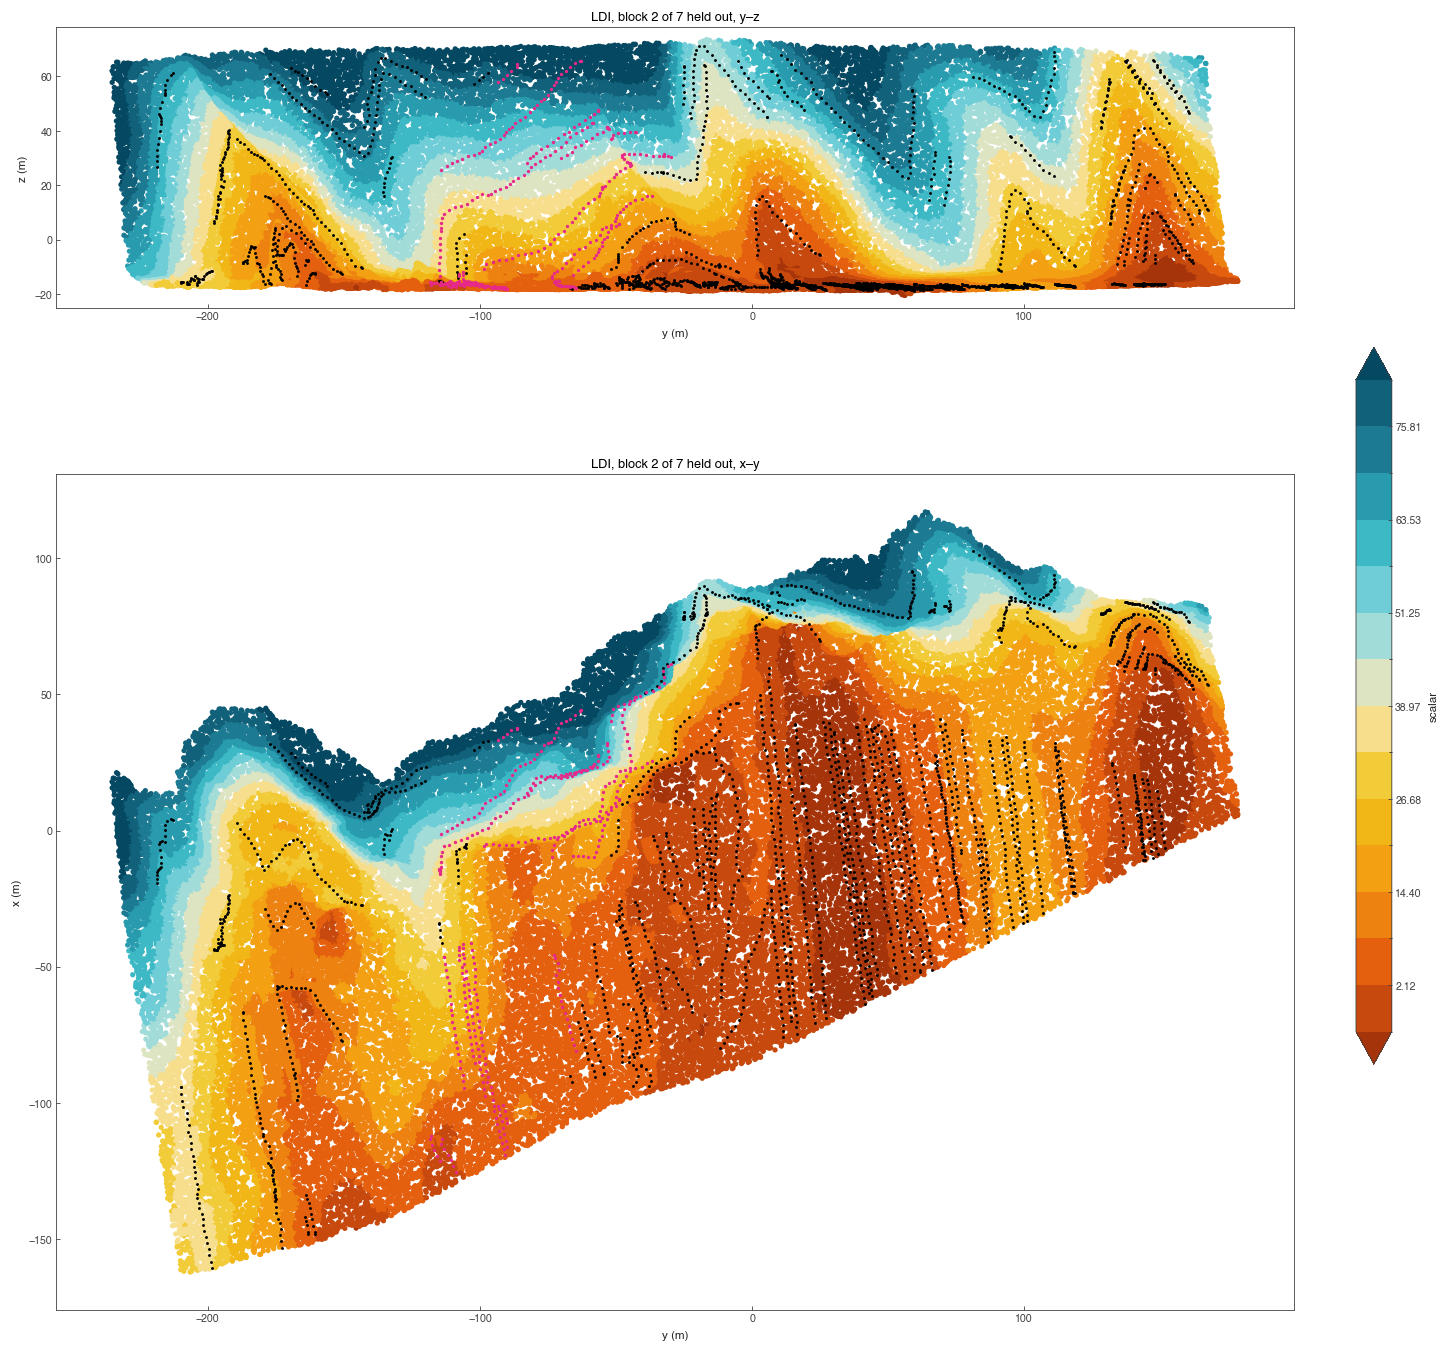

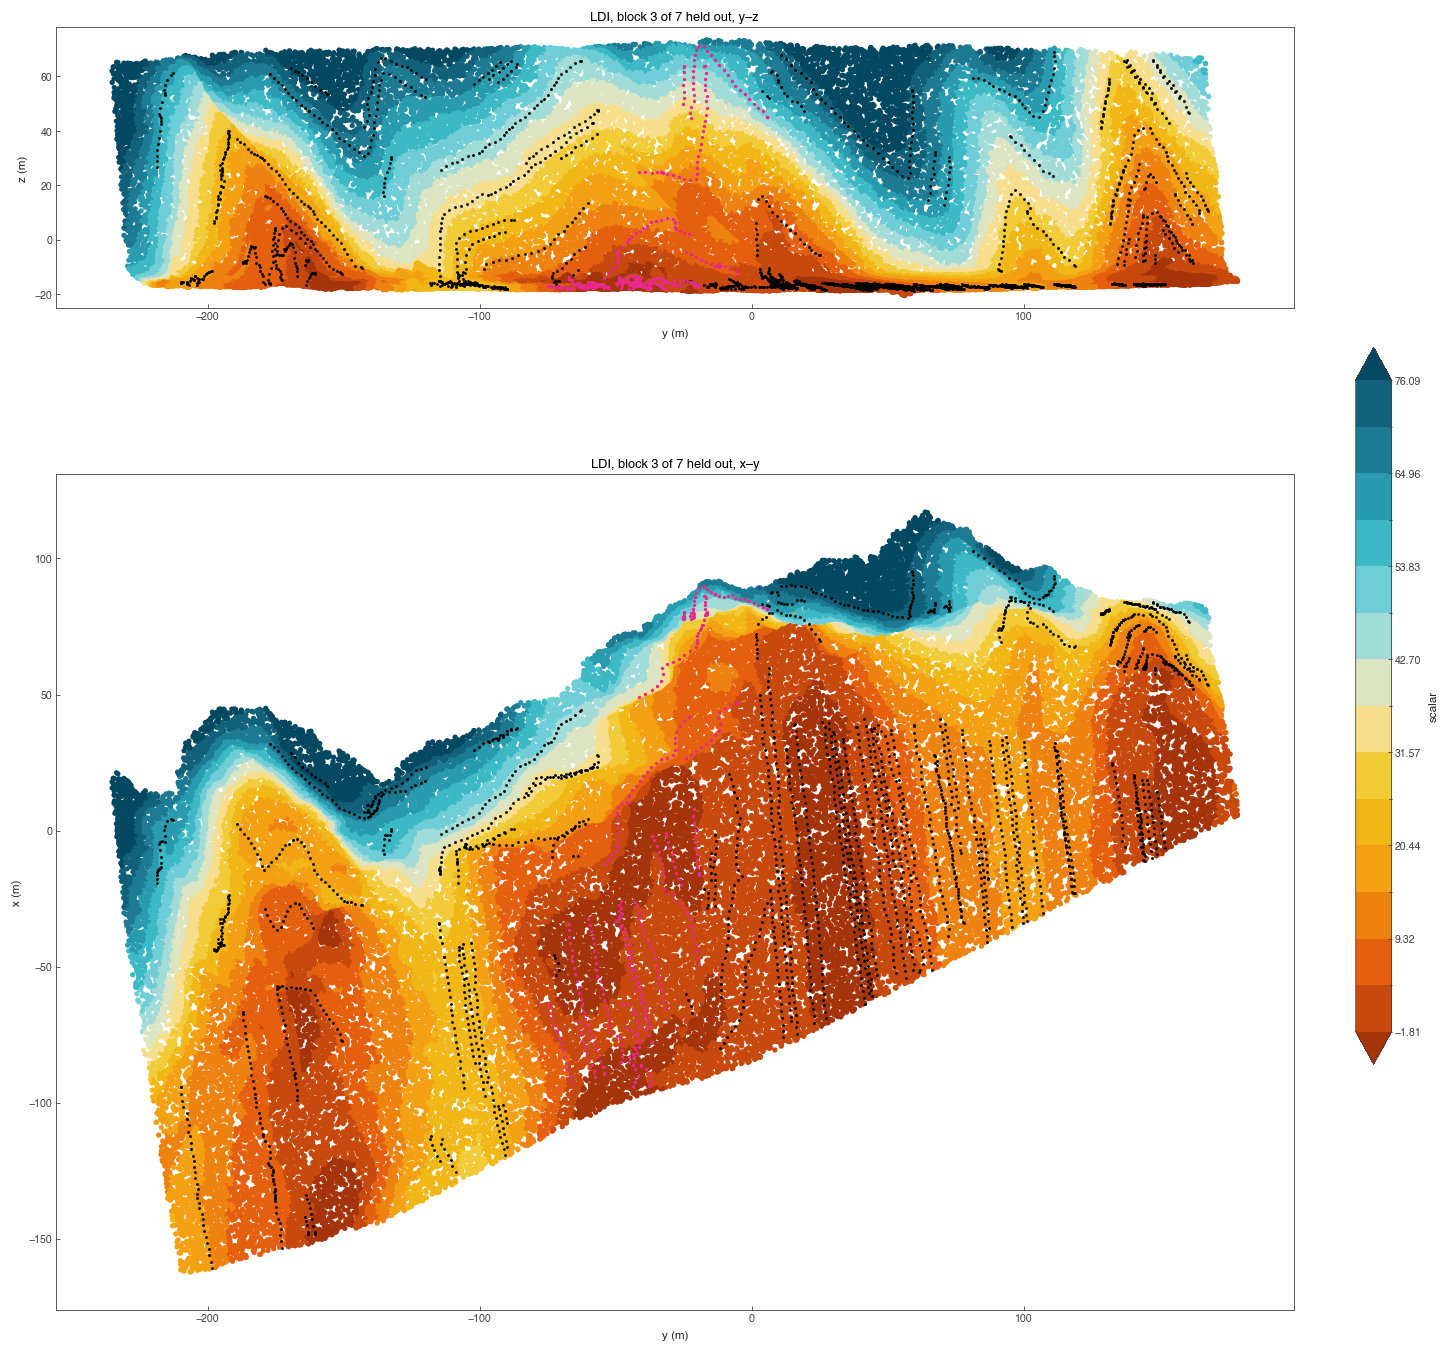

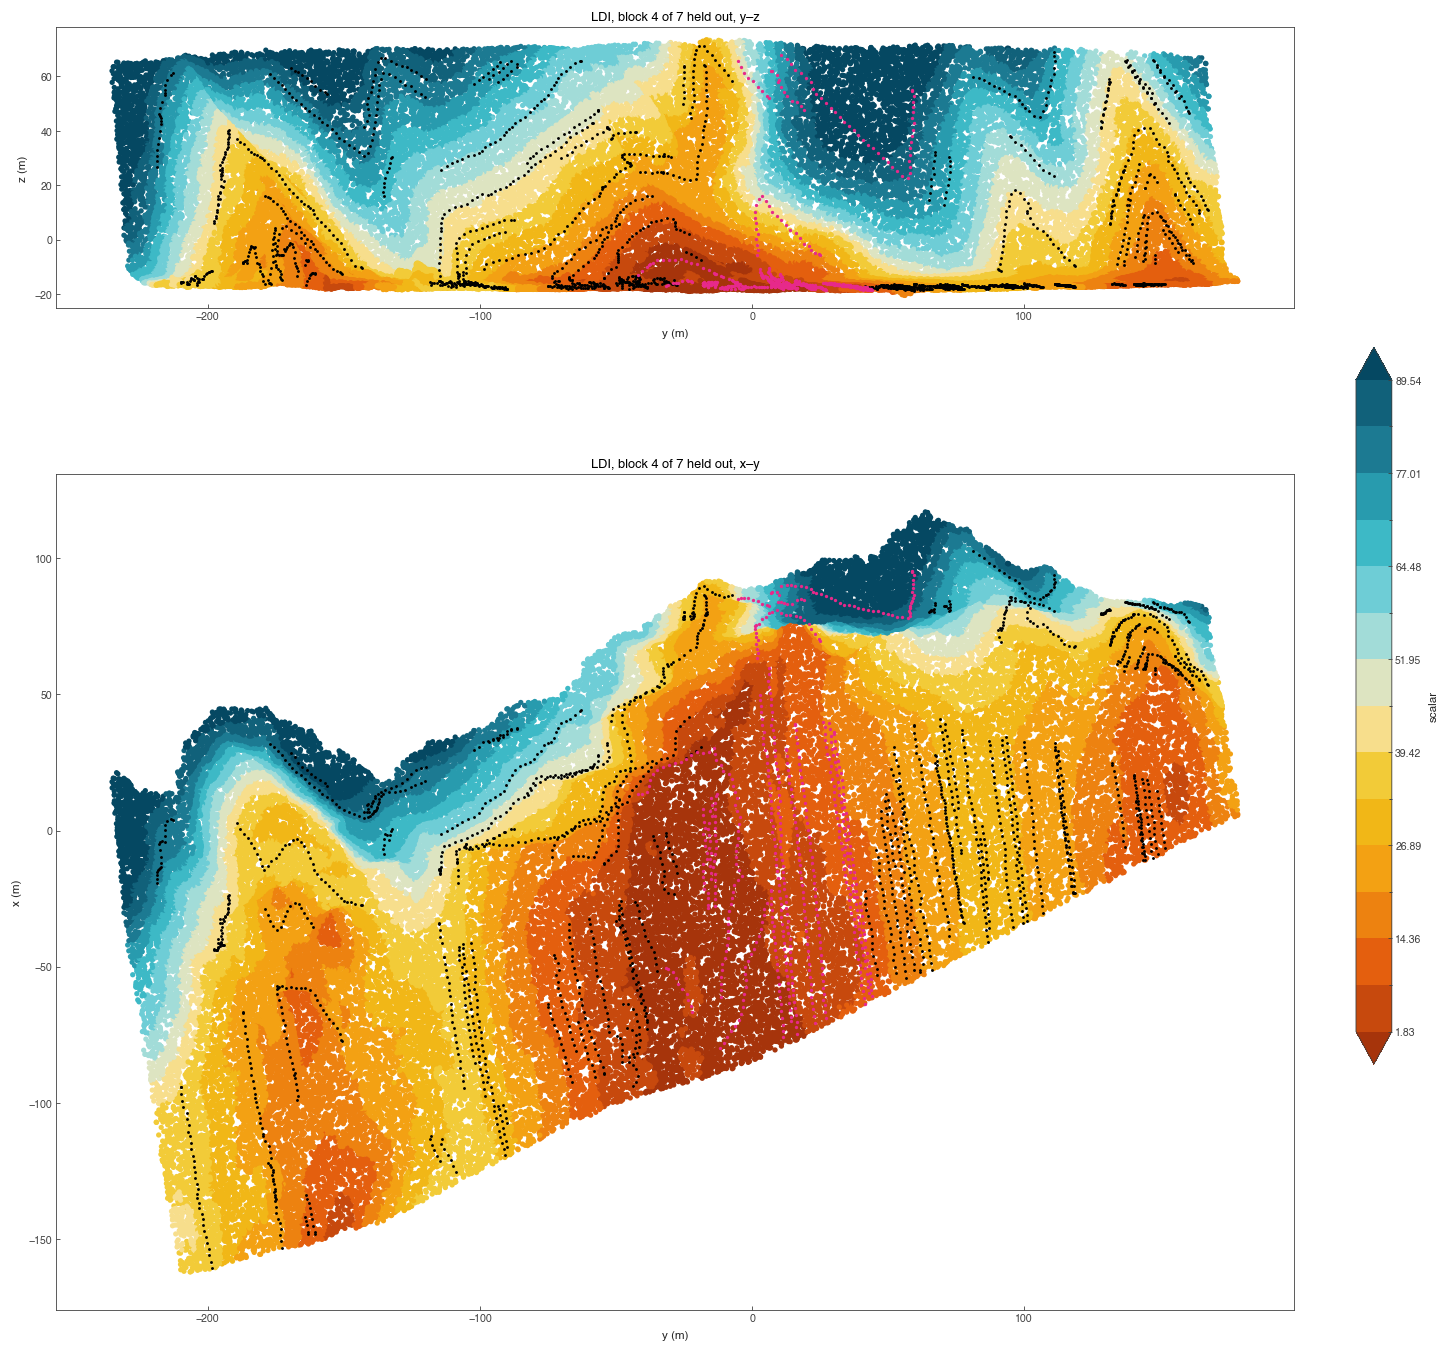

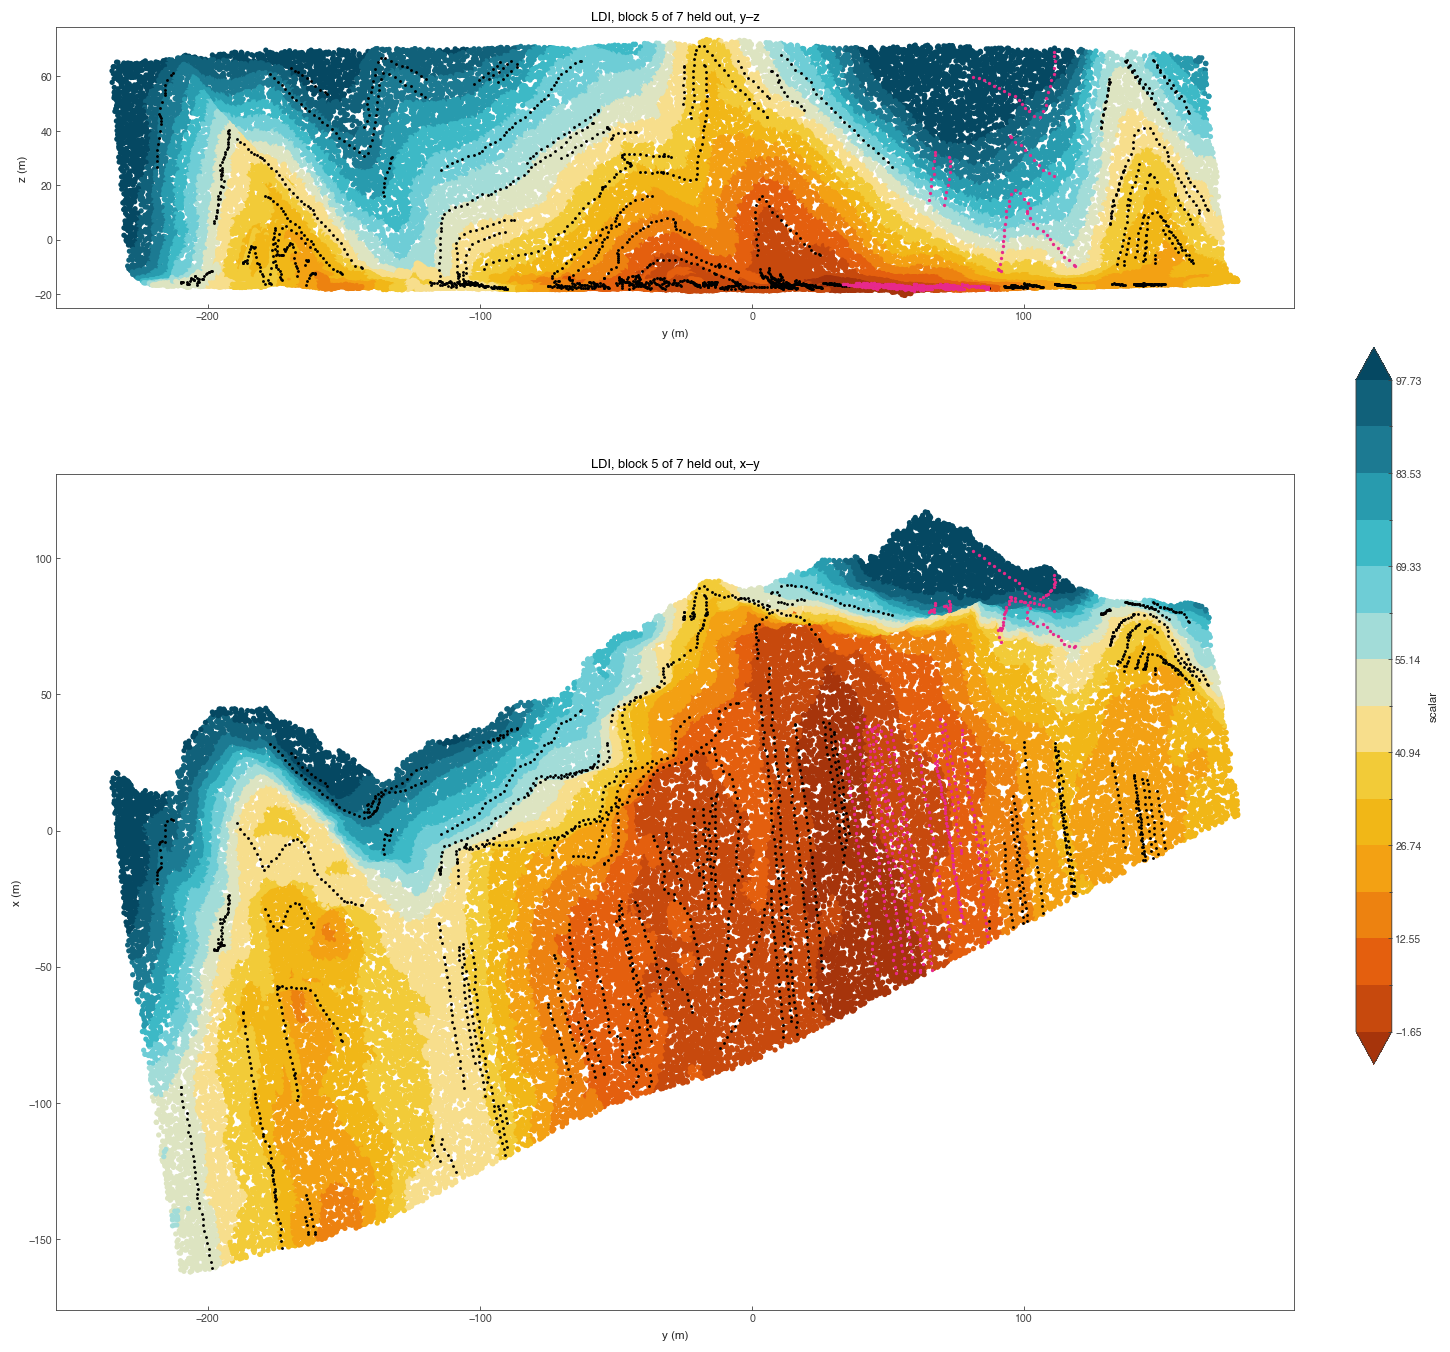

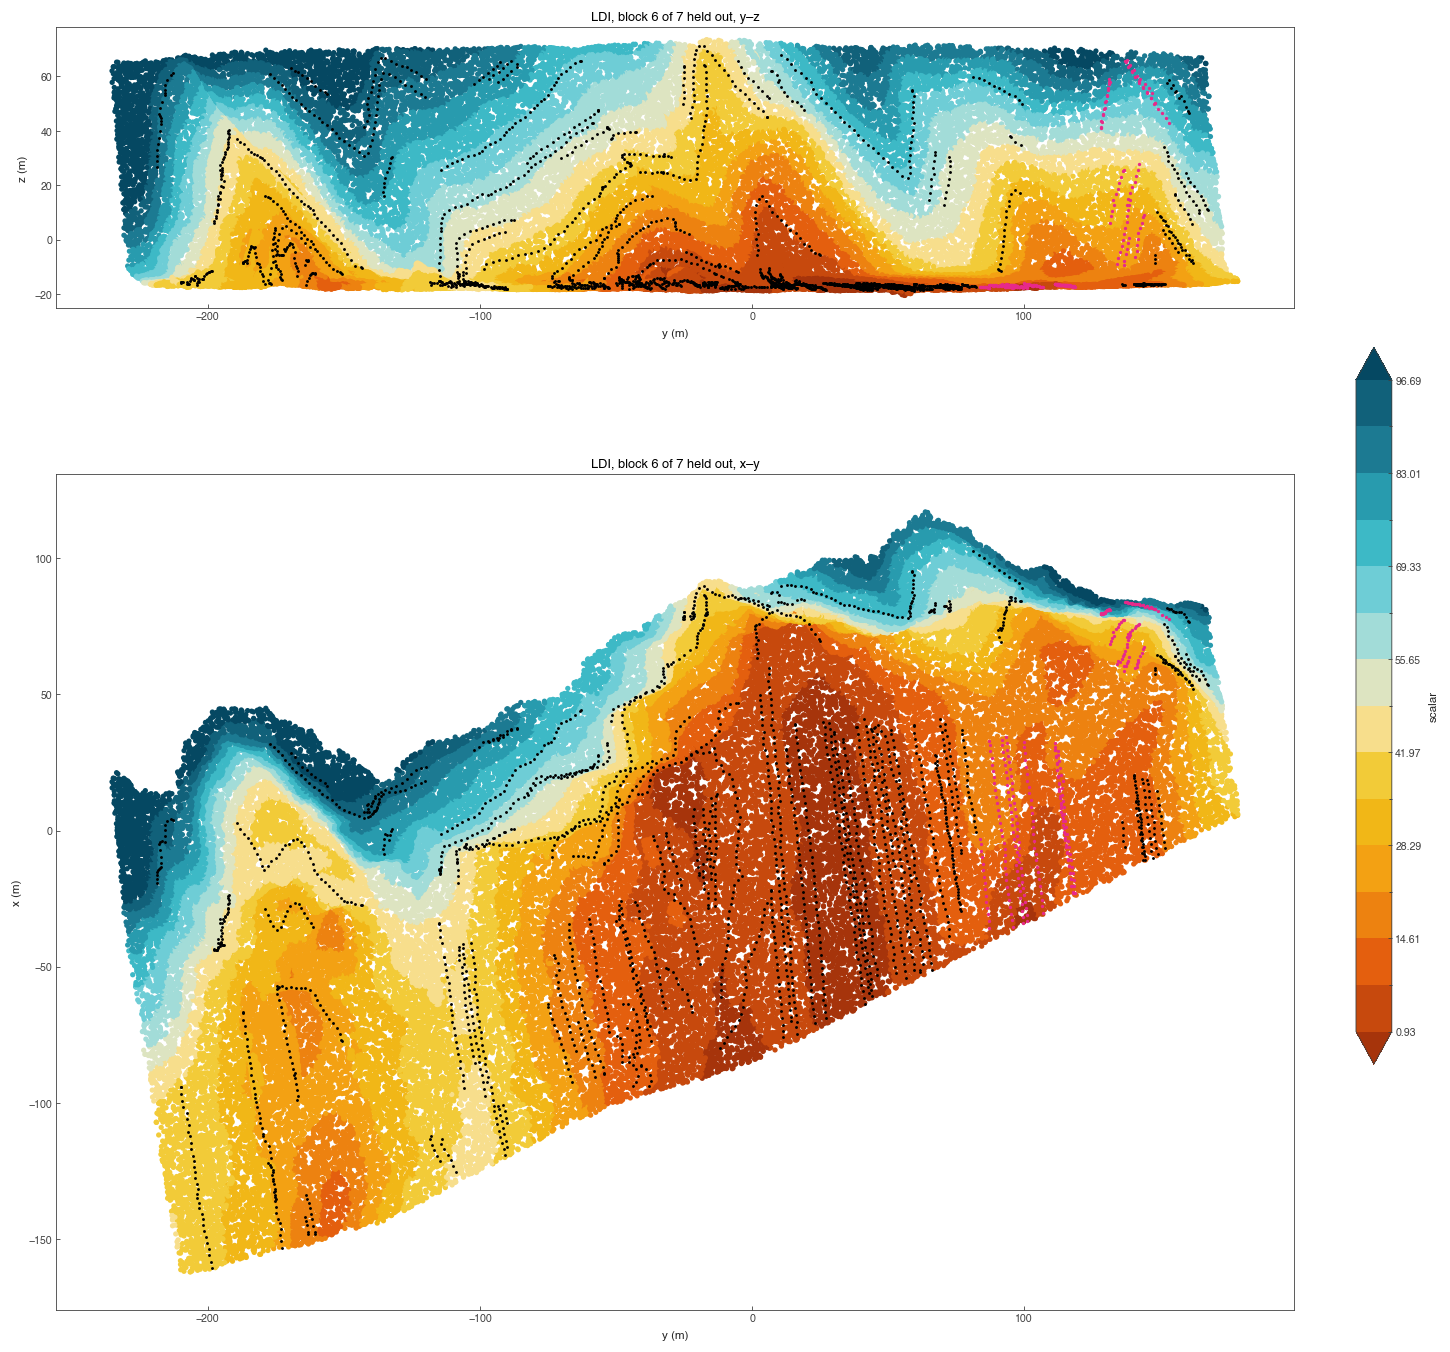

In [6]:
N_BANDS = 15
for model, event, f in fits:
    with torch.no_grad():
        phi_c = np.concatenate([np.asarray(model.predict(torch.as_tensor(c, dtype=curlew.dtype, device=curlew.device),
                                                         litho=False).scalar).ravel()
                                for c in np.array_split(cloud_xyz, max(1, len(cloud_xyz) // 50_000))])
    edges_b = diagnostics.evenly_spaced_levels(list(event.getIsovalues().values()), N_BANDS)
    fig, axs = diagnostics.plot_cloud_scalar(cloud_xyz, phi_c, edges_b, lines=f["train"], size=10.,
                                             title=f"LDI, block {f['block'] + 1} of 7 held out")
    for ax, (i, j) in zip(axs, ((1, 2), (1, 0))):
        for k in f["test"]:
            ax.scatter(traces[k][:, i], traces[k][:, j], s=4, color="#E7298A", linewidths=0, zorder=4)
    plt.show()